In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron
#Used for simple linear classification

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
#Sequential lets you build a neural network layer-by-layer in keras.

from tensorflow.keras.layers import Dense   #Dense makes final Predictions
from tensorflow.keras.layers import Conv2D   #Conv2D extracts features
from tensorflow.keras.layers import Flatten #Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D  #MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout       #Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical #converts numeric class labels into one-hot encoded format for training classification models

In [3]:
df = pd.read_csv("mnist_train.csv")
df_test = pd.read_csv("mnist_test.csv")

df

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59997,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df.shape

(60000, 785)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [7]:
df.isnull().sum()

label    0
1x1      0
1x2      0
1x3      0
1x4      0
        ..
28x24    0
28x25    0
28x26    0
28x27    0
28x28    0
Length: 785, dtype: int64

In [9]:
#preprocess
X_train = df.drop("label", axis=1).values
y_train = df["label"].values
X_test = df_test.drop("label", axis=1).values
y_test = df_test["label"].values

In [10]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [11]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)


In [24]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [25]:
perceptron = Sequential({
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")
})

In [31]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

In [27]:
history_percp = perceptron.fit(X_train_img, y_train_cat, epochs=5,
batch_size = 32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8199 - loss: 0.7684 - val_accuracy: 0.8832 - val_loss: 0.4772
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8810 - loss: 0.4553 - val_accuracy: 0.8964 - val_loss: 0.3981
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8914 - loss: 0.4028 - val_accuracy: 0.9024 - val_loss: 0.3655
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8974 - loss: 0.3764 - val_accuracy: 0.9067 - val_loss: 0.3471
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9010 - loss: 0.3598 - val_accuracy: 0.9096 - val_loss: 0.3339


In [32]:
acc_percp = perceptron.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [33]:
acc_percp

0.1598999947309494

In [34]:
#ANN
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [35]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=["accuracy"])

In [36]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32,
validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9288 - loss: 0.2417 - val_accuracy: 0.9596 - val_loss: 0.1299
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9678 - loss: 0.1056 - val_accuracy: 0.9734 - val_loss: 0.0877
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9771 - loss: 0.0723 - val_accuracy: 0.9727 - val_loss: 0.0865
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9818 - loss: 0.0560 - val_accuracy: 0.9750 - val_loss: 0.0815
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9862 - loss: 0.0430 - val_accuracy: 0.9754 - val_loss: 0.0811


In [37]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [38]:
acc_ann

0.9753999710083008

In [39]:
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [40]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [41]:
cnn.compile(optimizer='adam', loss="categorical_crossentropy", metrics=["accuracy"])

In [42]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=5, batch_size=32,
validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.9377 - loss: 0.2021 - val_accuracy: 0.9858 - val_loss: 0.0423
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9783 - loss: 0.0717 - val_accuracy: 0.9894 - val_loss: 0.0313
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9834 - loss: 0.0558 - val_accuracy: 0.9896 - val_loss: 0.0292
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9874 - loss: 0.0427 - val_accuracy: 0.9917 - val_loss: 0.0252
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9888 - loss: 0.0377 - val_accuracy: 0.9930 - val_loss: 0.0225


In [43]:
acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]

In [44]:
acc_cnn

0.9929999709129333

In [ ]:
def plot_training(history, title):
  plt.figure(figsize=(12,4))
  plt.subplot(1,2,1)
  plt.plot(history.history['accuracy'], label="Train")
  plt.plot(history.history["val_accuracy"], label="Val")
  plt.title(f"{title} Accuracy")
  plt.legend()

  plt.subplot(1,2,2)
  plt.plot(history.history['loss'], label="Train")
  plt.plot(history.history['val_loss'], label="Val")
  plt.title(f"{title} Loss")
  plt.legend()
  plt.show()

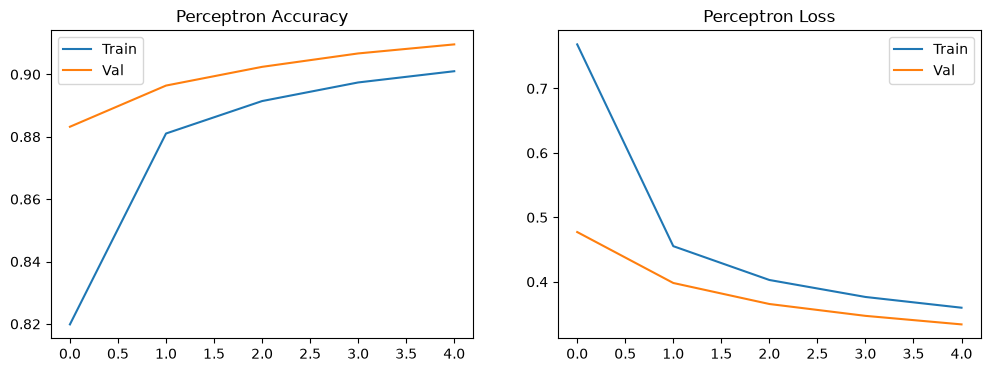

In [46]:
plot_training(history_percp, "Perceptron")

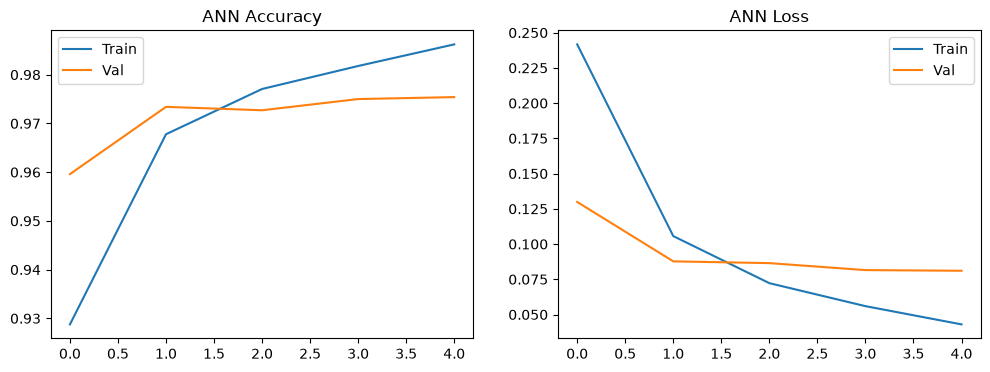

In [47]:
plot_training(history_ann, "ANN")

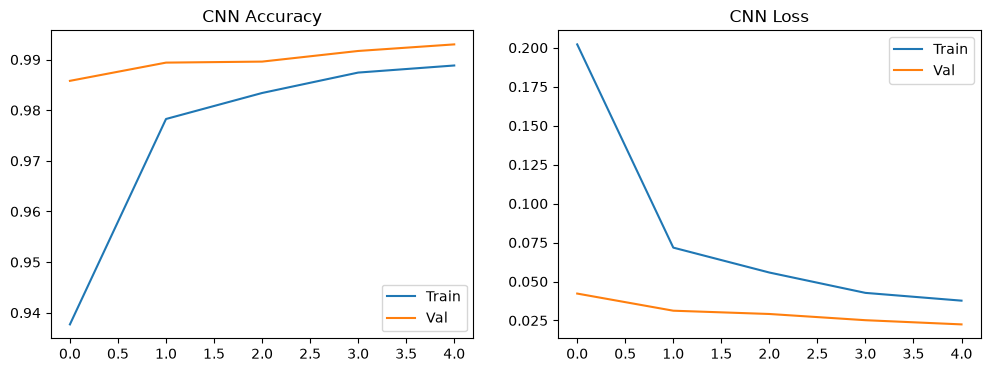

In [48]:
plot_training(history_cnn, "CNN")

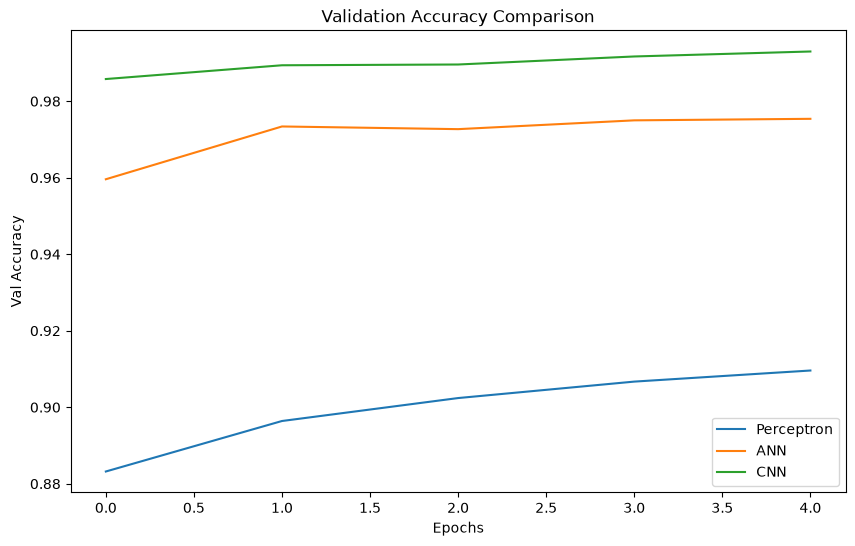

In [49]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [50]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
  idxs = np.random.choice(len(X), n, replace=False)
  plt.figure(figsize=(15, 6))
  for i, idx in enumerate(idxs):
    plt.subplot(2, n, i+1)
    plt.imshow(X[idx].reshape(28,28), cmap='gray')
    plt.axis("off")
    plt.title(f"True: {y_true[idx]}")
    preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
            for model, name in zip(models, model_names)]
    plt.subplot(2, n, n+i+1)
    plt.axis("off")
    plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


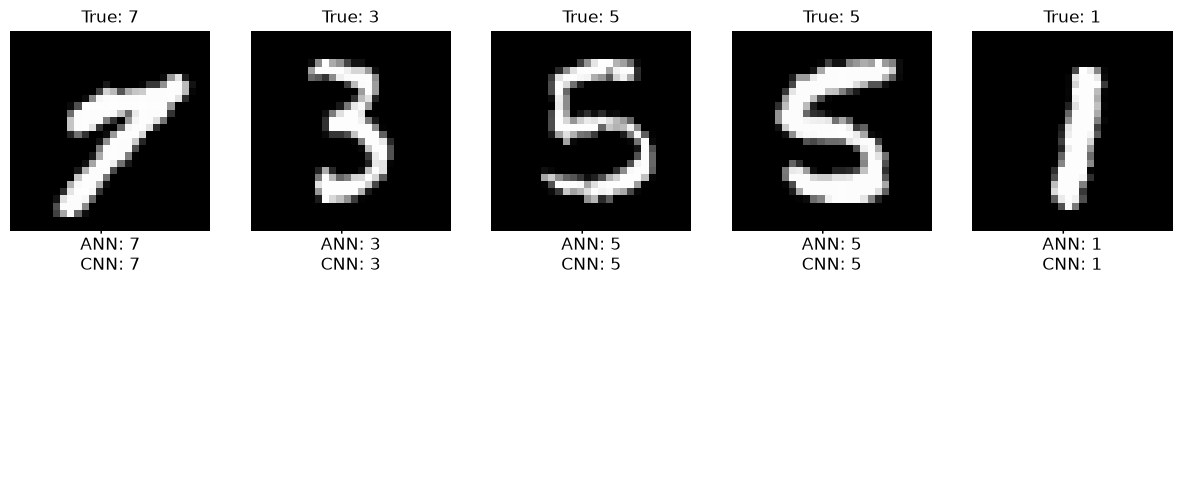

In [51]:
show_side_by_side([perceptron, ann, cnn], ['Perceptron', "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)